# 09 — Pronóstico de series de tiempo del Parque Tunari

## Qué hace este notebook

Parte de lo que **ya tenemos armonizado** (tabla `serie_mensual` del paquete, área `parque-tunari`) y compara
**cuatro familias de modelos** para pronosticar el índice mensual hasta diciembre de 2027:

| # | Familia | Idea |
|---|---|---|
| 1 | Referencia ingenua estacional | «Este mes será como el mismo mes de antes» (1a: último año disponible; 1b: mediana histórica del mes) |
| 2 | Regresión de conteos binomial negativa | La misma familia que usan nuestras alertas: estacionalidad y control de época, **sin tendencia** (2b: la misma con tendencia, como variante) |
| 3 | Series de tiempo clásicas | 3a: suavizado exponencial (ETS) · 3b: SARIMA, ambos sobre `log(1 + índice)` |
| 4 | Anual con tendencia | Recta de Theil–Sen sobre el índice anual (la de la tabla `tendencias`), repartida por mes con el perfil estacional |

Se agregan dos **extras**: la variante 2b (con tendencia) y una **combinación** (promedio de 2, 3a y 3b), solo para ver si ayudan.

## Qué se pronostica y en qué unidad

- Columna **`indice_para_alertas`** de `serie_mensual`: celdas-día por mes **en unidades MODIS-equivalentes**
  (antes de feb-2012 es MODIS; después, VIIRS Suomi-NPP ÷ factor 2,8715). Es el mismo índice con el que se calculan las alertas.
- Para la regresión de conteos se usa `conteo_base_alertas` (el conteo bruto de la época) con el factor como compensación,
  de modo que su pronóstico queda en la misma unidad que el índice.
- El Tunari es la **única** área con índice `mixto_calibrado` (`calibrado_localmente_en_tunari`), por eso es la serie larga confiable.

## Cómo se compara (importante)

**Validación rodante**: para cada año objetivo (2019–2026) se entrena **solo con datos hasta octubre del año anterior**
y se pronostican los meses de ese año. Es exactamente la situación de 2027: hoy tenemos datos hasta octubre de 2026.
Así ningún modelo «ve el futuro» al ajustarse, y el error que se mide se parece al que esperaríamos de verdad.

**Salvedad:** el factor de armonización (2,8715) se calculó con 2013–2025, de modo que el índice con el que se evalúa ya contiene una fuga leve de información posterior a cada corte. Afecta por igual a todos los modelos (la comparación sigue siendo justa), pero el error real de 2027 podría ser algo mayor.

In [1]:
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd()
PAQUETE = ROOT / "entrega_backend" / "datos"
SALIDA = ROOT / "DATOS_PROCESADOS" / "pronostico"
SALIDA.mkdir(parents=True, exist_ok=True)

AREA = "parque-tunari"
FACTOR = float(pd.read_csv(PAQUETE / "parametros.csv").set_index("clave").loc["factor_viirs_por_modis", "valor"])

serie = pd.read_csv(PAQUETE / "serie_mensual.csv", parse_dates=["mes"])
t = serie[serie.area_id == AREA].sort_values("mes").set_index("mes").asfreq("MS")
# Factor de cada mes: 1 con MODIS solo; el factor del proyecto cuando el índice se arma con VIIRS.
t["factor_epoca"] = np.where(t.era == "MODIS_solo", 1.0, FACTOR)

print(f"Factor VIIRS/MODIS: {FACTOR}")
print(f"Meses: {len(t)}  ({t.index.min():%Y-%m} a {t.index.max():%Y-%m}); meses faltantes: {int(t.indice_para_alertas.isna().sum())}")
print("Calidad del índice:", t.calidad_indice.unique().tolist())
# El índice es el conteo dividido por el factor de su época: lo comprobamos.
print("Máx |índice − conteo/factor| =", float((t.indice_para_alertas - t.conteo_base_alertas / t.factor_epoca).abs().max()))
t[["era", "conteo_base_alertas", "factor_epoca", "indice_para_alertas"]].tail(6)

Factor VIIRS/MODIS: 2.8715
Meses: 303  (2001-08 a 2026-10); meses faltantes: 0
Calidad del índice: ['calibrado_localmente_en_tunari']
Máx |índice − conteo/factor| = 0.00016724306130555533


,era,conteo_base_alertas,factor_epoca,indice_para_alertas
mes,,,,
2026-05-01,MODIS+VIIRS-SNPP,2.0,2.8715,0.696497
2026-06-01,MODIS+VIIRS-SNPP,14.0,2.8715,4.875479
2026-07-01,MODIS+VIIRS-SNPP,30.0,2.8715,10.447454
2026-08-01,MODIS+VIIRS-SNPP,39.0,2.8715,13.581691
2026-09-01,MODIS+VIIRS-SNPP,26.0,2.8715,9.054460
2026-10-01,MODIS+VIIRS-SNPP,23.0,2.8715,8.009715


## 1. La serie y su estacionalidad

El fuego en el Tunari tiene **temporada** (julio–octubre) y casi nada en la época húmeda. Esa forma repetida es lo que
cualquier pronóstico razonable debe capturar. El tamaño de cada temporada, en cambio, varía mucho de un año a otro
(2020: ~93 celdas-día; 2021: ~23), y eso es lo que **ningún modelo puede adivinar** con solo la historia de la serie.

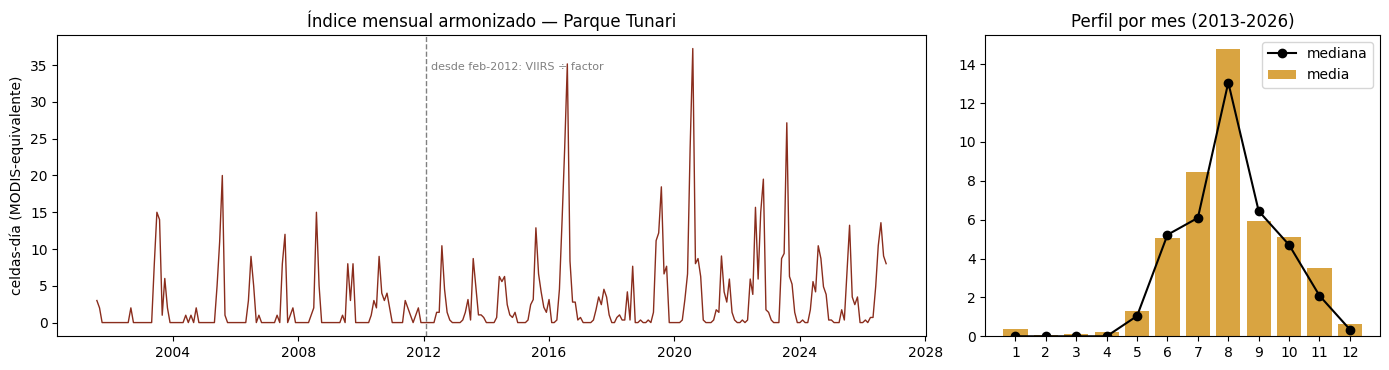

Índice anual 2013-2025: {2013: 21.6, 2014: 24.4, 2015: 33.1, 2016: 95.1, 2017: 17.8, 2018: 15.0, 2019: 57.8, 2020: 94.4, 2021: 27.2, 2022: 68.3, 2023: 59.9, 2024: 40.0, 2025: 31.7}


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(t.index, t.indice_para_alertas, lw=1, color="#8a2d1d")
ax[0].axvline(pd.Timestamp("2012-02-01"), color="gray", ls="--", lw=1)
ax[0].text(pd.Timestamp("2012-04-01"), t.indice_para_alertas.max() * 0.92, "desde feb-2012: VIIRS ÷ factor", fontsize=8, color="gray")
ax[0].set_title("Índice mensual armonizado — Parque Tunari"); ax[0].set_ylabel("celdas-día (MODIS-equivalente)")
perfil = t[t.index.year >= 2013].groupby(t[t.index.year >= 2013].index.month).indice_para_alertas.agg(["median", "mean"])
ax[1].bar(perfil.index, perfil["mean"], color="#d9a441", label="media"); ax[1].plot(perfil.index, perfil["median"], "ko-", label="mediana")
ax[1].set_title("Perfil por mes (2013-2026)"); ax[1].set_xticks(range(1, 13)); ax[1].legend()
plt.tight_layout(); plt.show()
anual = t[t.index.year.isin(range(2013, 2026))].groupby(lambda d: d.year).indice_para_alertas.sum()
print("Índice anual 2013-2025:", anual.round(1).to_dict())

## 2. Los modelos

Cada función recibe **solo** los datos hasta una fecha de corte (`origen`) y devuelve, para los meses a pronosticar,
el valor esperado y una banda del 90 % (`limite_inferior_p05` y `limite_superior_p95`, los mismos nombres que usa `serie_mensual`).

- **1a / 1b**: sin estadística. 1a repite el último mismo-mes disponible; 1b usa la mediana (y los percentiles 5 y 95) de ese mes en toda la historia.
- **2**: regresión binomial negativa sobre el **conteo**, con 2 armónicos anuales (la forma de la temporada), un **control de época**
  (0 hasta ene-2012, 1 desde feb-2012) y el factor como compensación. **No lleva tendencia**: la prueba de Mann–Kendall del paquete
  (`tendencias`, 2013–2025) da p = 0,435, es decir, no hay tendencia demostrable, y extrapolarla (variante **2b**) infla el pronóstico.
  La dispersión se estima de los datos y la banda sale de la propia distribución.
- **3a / 3b**: ETS y SARIMA sobre `log(1 + índice)` (para que sea positivo y menos asimétrico); al volver a la escala original
  se corrige el sesgo del logaritmo (se pronostica la media, no la mediana).
- **4**: índice **anual** (suma de los 12 meses de `indice_para_alertas`) de los años completos desde 2013, recta de Theil–Sen (robusta), y reparto mensual con la proporción media
  de cada mes. La banda sale de los residuos anuales (pocos puntos: es una banda aproximada).

In [3]:
MESES_HIST_MIN = 12 * 5  # un modelo no se ajusta con menos de 5 años


def futuro(origen, hasta):
    return pd.date_range(origen + pd.offsets.MonthBegin(1), hasta, freq="MS")


def disenio(idx, tendencia=False, k=2):
    # Matriz de la regresión: constante, armónicos (forma de la temporada), control de época VIIRS y, opcional, tendencia
    m = np.asarray(idx.month)
    cols = {"const": np.ones(len(idx))}
    if tendencia:
        cols["tiempo"] = (np.asarray(idx.year) + (m - 1) / 12 - 2013) / 10
    for j in range(1, k + 1):
        cols[f"sin{j}"] = np.sin(2 * np.pi * j * m / 12)
        cols[f"cos{j}"] = np.cos(2 * np.pi * j * m / 12)
    # 1 desde feb-2012 (índice con VIIRS ÷ factor): absorbe cualquier diferencia de nivel entre épocas
    cols["epoca_viirs"] = (idx >= pd.Timestamp("2012-02-01")).astype(float)
    return pd.DataFrame(cols, index=idx)


def pron_ingenuo(d, fut):
    # 1a: último mismo-mes disponible a la fecha de corte; 1b: mediana histórica del mes (con p05 y p95)
    y = d.indice_para_alertas
    a = pd.Series([y[y.index.month == m.month].iloc[-1] for m in fut], index=fut)
    g = y.groupby(y.index.month)
    b = pd.DataFrame({"esperado": [g.get_group(m.month).median() for m in fut],
                      "p05": [g.get_group(m.month).quantile(0.05) for m in fut],
                      "p95": [g.get_group(m.month).quantile(0.95) for m in fut]}, index=fut)
    return {"1a_ingenuo_mismo_mes": pd.DataFrame({"esperado": a, "p05": np.nan, "p95": np.nan}),
            "1b_mediana_historica_mes": b}


def _binomial_negativa(d, fut, tendencia):
    X = disenio(d.index, tendencia)
    y = d.conteo_base_alertas.astype(float)
    off = np.log(d.factor_epoca)
    mu = sm.GLM(y, X, family=sm.families.Poisson(), offset=off).fit().mu
    for _ in range(3):  # dispersión por regresión auxiliar (Cameron–Trivedi), refinada
        alfa = max(float(np.sum((y - mu) ** 2 - mu) / np.sum(mu ** 2)), 0.05)
        ajuste = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alfa), offset=off).fit()
        mu = ajuste.mu
    Xf = disenio(fut, tendencia)
    media_idx = np.exp(Xf.values @ ajuste.params.values)          # índice esperado (MODIS-equivalente)
    mu_cnt = media_idx * FACTOR                                    # el futuro es de la época VIIRS
    r = 1.0 / alfa
    p = r / (r + mu_cnt)
    out = pd.DataFrame({"esperado": media_idx, "p05": stats.nbinom.ppf(0.05, r, p) / FACTOR,
                        "p95": stats.nbinom.ppf(0.95, r, p) / FACTOR}, index=fut)
    out.attrs["dispersion"] = alfa
    out.attrs["coeficientes"] = ajuste.params.round(3).to_dict()
    return out


def pron_binomial_negativa(d, fut):
    # 2: sin tendencia (la de 2013-2025 no es significativa: Mann-Kendall p = 0,435). 2b: con tendencia lineal (variante)
    return {"2_binomial_negativa": _binomial_negativa(d, fut, tendencia=False),
            "2b_bn_con_tendencia": _binomial_negativa(d, fut, tendencia=True)}


def _volver(media_log, var_log, lo_log, hi_log):
    # Corrección del sesgo del logaritmo: media de una lognormal = exp(mu + var/2)
    return np.expm1(media_log + var_log / 2), np.expm1(lo_log), np.expm1(hi_log)


def pron_ets_sarima(d, fut):
    ylog = np.log1p(d.indice_para_alertas.astype(float))
    ylog.index.freq = "MS"
    n = len(fut)
    res = {}
    ets = ETSModel(ylog, error="add", trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit(disp=False)
    pr = ets.get_prediction(start=fut[0], end=fut[-1]).summary_frame(alpha=0.10)
    e, lo, hi = _volver(pr["mean"].values, float(np.var(ets.resid)), pr["pi_lower"].values, pr["pi_upper"].values)
    res["3a_ets_log"] = pd.DataFrame({"esperado": e, "p05": np.maximum(lo, 0), "p95": hi}, index=fut)
    sar = SARIMAX(ylog, order=(1, 0, 1), seasonal_order=(1, 0, 1, 12), trend="c").fit(disp=False, maxiter=200)
    fc = sar.get_forecast(n)
    ci = fc.conf_int(alpha=0.10)
    e, lo, hi = _volver(fc.predicted_mean.values, float(sar.params["sigma2"]), ci.iloc[:, 0].values, ci.iloc[:, 1].values)
    res["3b_sarima_log"] = pd.DataFrame({"esperado": e, "p05": np.maximum(lo, 0), "p95": hi}, index=fut)
    return res


def pron_anual_sen(d, fut, anual_tabla):
    # Solo años completos de la era VIIRS que ya estaban cerrados a la fecha de corte
    ultimo_completo = d.index.max().year if d.index.max().month == 12 else d.index.max().year - 1
    a = anual_tabla[(anual_tabla.index >= 2013) & (anual_tabla.index <= ultimo_completo)]
    pend, inter, _, _ = stats.theilslopes(a.values, a.index.values)
    resid = a.values - (inter + pend * a.index.values)
    q05, q95 = np.quantile(resid, [0.05, 0.95])
    mens = d[d.index.year.isin(a.index)].indice_para_alertas
    cuota = (mens.groupby([mens.index.year, mens.index.month]).sum().unstack(0) / a.values).mean(axis=1)  # proporción media del año
    filas = []
    for m in fut:
        total = max(inter + pend * m.year, 0.0)
        filas.append((total * cuota[m.month], max(total + q05, 0) * cuota[m.month], max(total + q95, 0) * cuota[m.month]))
    return {"4_anual_sen": pd.DataFrame(filas, columns=["esperado", "p05", "p95"], index=fut)}


# Índice anual = suma de los 12 meses de indice_para_alertas (la MISMA variable que se pronostica y con la que se evalúa).
# No se usa la escala anual de serie_agregada porque combina MODIS y VIIRS de otra forma y difiere unas celdas-día por año.
_g = t.dropna(subset=["indice_para_alertas"]).groupby(lambda d: d.year).indice_para_alertas.agg(["sum", "count"])
ANUAL = _g[_g["count"] == 12]["sum"]


def pronosticar(origen, hasta):
    d = t.loc[:origen].dropna(subset=["indice_para_alertas"])
    fut = futuro(origen, hasta)
    res = {}
    res.update(pron_ingenuo(d, fut))
    res.update(pron_binomial_negativa(d, fut))
    res.update(pron_ets_sarima(d, fut))
    res.update(pron_anual_sen(d, fut, ANUAL))
    comb = sum(res[k] for k in ("2_binomial_negativa", "3a_ets_log", "3b_sarima_log")) / 3
    res["5_combinacion_2_3a_3b"] = comb
    return res


ejemplo = pronosticar(pd.Timestamp("2025-10-01"), pd.Timestamp("2026-10-01"))
pd.concat({k: v.esperado.round(1) for k, v in ejemplo.items()}, axis=1).head(14)

,1a_ingenuo_mismo_mes,1b_mediana_historica_mes,2_binomial_negativa,2b_bn_con_tendencia,3a_ets_log,3b_sarima_log,4_anual_sen,5_combinacion_2_3a_3b
2025-11-01,3.8,1.2,2.4,3.3,1.9,2.1,4.1,2.2
2025-12-01,0.3,0.0,0.9,1.3,0.8,0.6,1.2,0.8
2026-01-01,0.3,0.0,0.3,0.4,0.5,0.4,0.5,0.4
2026-02-01,0.0,0.0,0.1,0.1,0.4,0.3,0.1,0.2
2026-03-01,0.0,0.0,0.1,0.1,0.4,0.3,0.3,0.3
2026-04-01,0.0,0.0,0.2,0.3,0.4,0.4,0.5,0.3
2026-05-01,1.7,0.3,1.0,1.5,1.1,1.3,1.7,1.1
2026-06-01,0.3,3.0,5.2,7.7,3.8,3.5,6.6,4.2
2026-07-01,6.6,4.2,12.0,17.9,5.7,6.1,10.2,7.9
2026-08-01,13.2,10.4,11.9,17.7,10.9,10.8,17.0,11.2


## 3. Validación rodante (2019–2026)

Para cada año objetivo se entrena hasta octubre del año anterior y se pronostica el año. Se mide:

- **WAPE mensual**: error absoluto total ÷ total observado (mismo indicador que usamos para la armonización; menos es mejor).
- **WAPE anual**: lo mismo, pero sumando los 12 meses de cada año completo (2019–2025). Es la medida más honesta, porque el error
  mensual está dominado por el ruido del conteo.
- **Sesgo**: si el modelo, en total, pronostica de más (+) o de menos (−).
- **Cobertura 90 %**: de cada 100 meses, cuántas veces el valor real cayó dentro de la banda. Un buen modelo debería estar cerca de 90.

In [4]:
filas = []
for anio in range(2019, 2027):
    origen = pd.Timestamp(f"{anio - 1}-10-01")
    objetivo_fin = min(pd.Timestamp(f"{anio}-12-01"), t.index.max())
    res = pronosticar(origen, objetivo_fin)
    for modelo, df in res.items():
        df = df[df.index.year == anio]
        df = df.assign(modelo=modelo, observado=t.loc[df.index, "indice_para_alertas"].values, origen_hasta=origen,
                       horizonte_meses=((df.index.year - origen.year) * 12 + df.index.month - origen.month))
        filas.append(df.reset_index(names="mes"))
bt = pd.concat(filas, ignore_index=True)
bt["anio"], bt["mes_num"] = bt.mes.dt.year, bt.mes.dt.month
print(f"Pronósticos evaluados: {len(bt)} ({bt.modelo.nunique()} modelos × {bt.groupby('modelo').size().iloc[0]} meses)")


def wape(o, e):
    return float(np.abs(o - e).sum() / o.sum())


def resumen(g):
    anual = g[g.anio <= 2025].groupby("anio").agg(o=("observado", "sum"), e=("esperado", "sum"))
    cubre = g.dropna(subset=["p05"])
    return pd.Series({
        "WAPE_mensual": wape(g.observado, g.esperado),
        "WAPE_anual": float(np.abs(anual.o - anual.e).sum() / anual.o.sum()),
        "sesgo": float((g.esperado.sum() - g.observado.sum()) / g.observado.sum()),
        "cobertura_90": float(((cubre.observado >= cubre.p05) & (cubre.observado <= cubre.p95)).mean()) if len(cubre) else np.nan,
    })


tabla = bt.groupby("modelo").apply(resumen)
tabla_fmt = (tabla * 100).round(1)
tabla_fmt.columns = ["WAPE mensual %", "WAPE anual %", "sesgo %", "cobertura 90 %"]
tabla_fmt

Pronósticos evaluados: 752 (8 modelos × 94 meses)


,WAPE mensual %,WAPE anual %,sesgo %,cobertura 90 %
modelo,,,,
1a_ingenuo_mismo_mes,78.9,60.1,-8.4,NaN
1b_mediana_historica_mes,65.9,62.6,-61.2,79.8
2_binomial_negativa,53.0,41.2,-18.4,91.5
2b_bn_con_tendencia,68.3,46.5,23.3,95.7
3a_ets_log,74.8,64.0,12.4,86.2
3b_sarima_log,61.5,47.7,-42.7,87.2
4_anual_sen,60.0,45.6,-13.0,43.6
5_combinacion_2_3a_3b,57.5,45.7,-16.2,89.4


Menor error ANUAL entre las opciones 1-4: 2_binomial_negativa (41.2%)
Menor error MENSUAL entre las opciones 1-4: 2_binomial_negativa (53.0%)
Referencia (1b, mediana del mes): mensual 65.9% · anual 62.6%


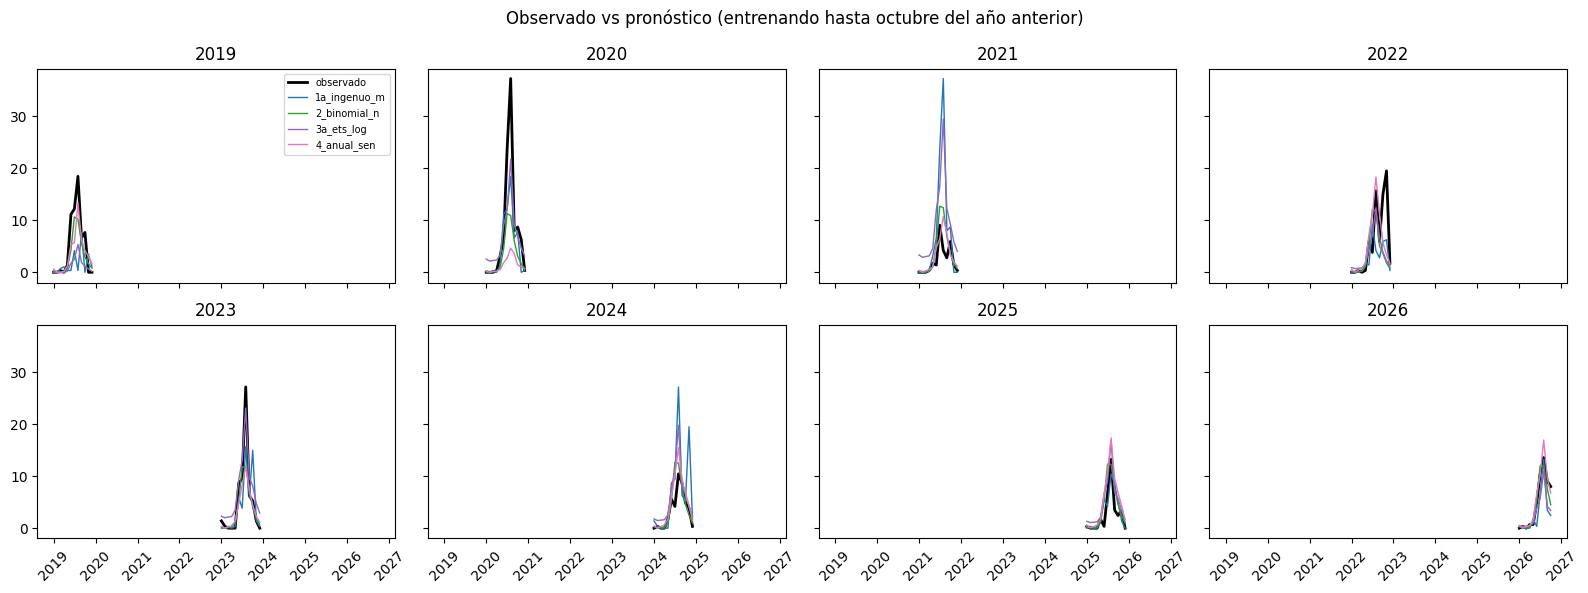

modelo,observado,1a_ingenuo_mismo_mes,1b_mediana_historica_mes,2_binomial_negativa,2b_bn_con_tendencia,3a_ets_log,3b_sarima_log,4_anual_sen,5_combinacion_2_3a_3b
anio,,,,,,,,,
2019,58.0,19.0,17.0,38.0,52.0,13.0,22.0,41.0,24.0
2020,94.0,58.0,18.0,40.0,57.0,79.0,26.0,17.0,48.0
2021,27.0,88.0,19.0,45.0,67.0,106.0,29.0,38.0,60.0
2022,68.0,32.0,20.0,44.0,66.0,41.0,31.0,62.0,39.0
2023,60.0,49.0,21.0,44.0,66.0,83.0,34.0,43.0,54.0
2024,40.0,80.0,22.0,48.0,81.0,69.0,33.0,57.0,50.0
2025,32.0,37.0,24.0,47.0,75.0,57.0,37.0,60.0,47.0


In [5]:
EXTRAS = ["2b_bn_con_tendencia", "5_combinacion_2_3a_3b"]
mejor = tabla.drop(index=EXTRAS).WAPE_anual.idxmin()
mejor_m = tabla.drop(index=EXTRAS).WAPE_mensual.idxmin()
print(f"Menor error ANUAL entre las opciones 1-4: {mejor} ({tabla.loc[mejor, 'WAPE_anual']:.1%})")
print(f"Menor error MENSUAL entre las opciones 1-4: {mejor_m} ({tabla.loc[mejor_m, 'WAPE_mensual']:.1%})")
base = tabla.loc["1b_mediana_historica_mes"]
print(f"Referencia (1b, mediana del mes): mensual {base.WAPE_mensual:.1%} · anual {base.WAPE_anual:.1%}")

fig, axs = plt.subplots(2, 4, figsize=(16, 6), sharex=True, sharey=True)
colores = plt.cm.tab10.colors
for ax, (anio, g) in zip(axs.ravel(), bt[bt.modelo == "2_binomial_negativa"].groupby("anio")):
    ax.plot(g.mes, g.observado, "k-", lw=2, label="observado")
    for i, (mod, gm) in enumerate(bt[bt.anio == anio].groupby("modelo")):
        if mod in ("1a_ingenuo_mismo_mes", "2_binomial_negativa", "3a_ets_log", "4_anual_sen"):
            ax.plot(gm.mes, gm.esperado, lw=1, color=colores[i], label=mod[:12])
    ax.set_title(str(anio)); ax.tick_params(axis="x", labelrotation=45)
axs[0, 0].legend(fontsize=7)
plt.suptitle("Observado vs pronóstico (entrenando hasta octubre del año anterior)"); plt.tight_layout(); plt.show()

anual_cmp = bt[bt.anio <= 2025].groupby(["anio", "modelo"]).esperado.sum().unstack().round(0)
anual_cmp.insert(0, "observado", bt[bt.anio <= 2025].drop_duplicates(["anio", "mes_num"]).groupby("anio").observado.sum().round(0))
anual_cmp

### Cómo leer estos resultados

- Si una opción **no mejora claramente a la referencia 1b**, no aporta: la mediana del mes ya captura casi todo lo predecible.
- Un **WAPE mensual alto no es un fracaso del modelo**: el conteo mensual es ruidoso (ya medimos que, aun con el modelo perfecto,
  el ruido de Poisson deja un piso de error mensual cercano al 30 %).
- Mire la **cobertura**: una banda que cubre mucho menos de 90 % está prometiendo más certeza de la que tiene.
- El **sesgo** importa para la demo: un modelo con sesgo fuerte hacia abajo subestimaría las temporadas intensas.

## 4. Pronóstico hasta diciembre de 2027

Se entrena con **toda la serie hasta octubre de 2026** y se pronostican noviembre-2026 a diciembre-2027 (14 meses).
La tabla de salida respeta el estilo de `serie_mensual`: `area_id`, `mes`, `anio`, `mes_num`, los límites `limite_inferior_p05`
y `limite_superior_p95`, y `calidad_indice`, más `modelo` y `horizonte_meses`.

Índice esperado de TODO 2027 por modelo (celdas-día MODIS-equivalentes):
modelo
1a_ingenuo_mismo_mes        51.2
1b_mediana_historica_mes    25.7
2_binomial_negativa         46.3
2b_bn_con_tendencia         67.0
3a_ets_log                  76.4
3b_sarima_log               39.6
4_anual_sen                 43.9
5_combinacion_2_3a_3b       54.1

Referencia: media anual 2019-2025 = 54.2; rango = 27.2–94.4


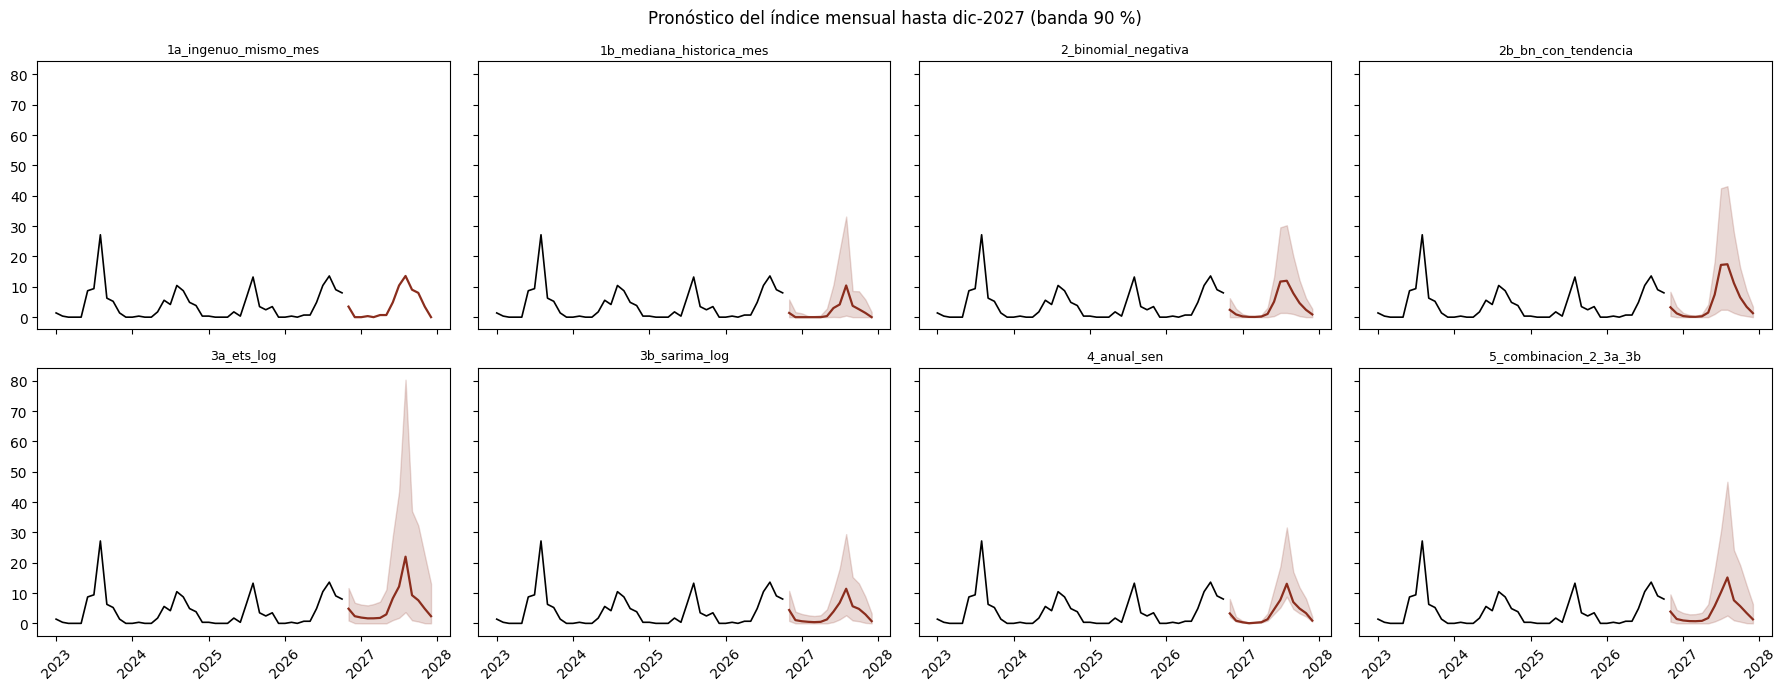

modelo,1a_ingenuo_mismo_mes,1b_mediana_historica_mes,2_binomial_negativa,2b_bn_con_tendencia,3a_ets_log,3b_sarima_log,4_anual_sen,5_combinacion_2_3a_3b
mes_num,,,,,,,,
1,0.0,0.0,0.3,0.4,1.9,0.7,0.4,1.0
2,0.3,0.0,0.1,0.1,1.6,0.5,0.0,0.7
3,0.0,0.0,0.1,0.1,1.7,0.4,0.2,0.7
4,0.7,0.0,0.2,0.3,1.8,0.5,0.4,0.8
5,0.7,0.3,1.0,1.5,3.0,1.3,1.3,1.8
6,4.9,3.0,5.1,7.4,8.2,3.9,4.6,5.7
7,10.4,4.2,11.7,17.2,12.1,6.8,7.7,10.2
8,13.6,10.4,12.0,17.4,22.0,11.4,13.1,15.1
9,9.1,3.7,7.9,11.2,9.3,5.6,7.0,7.6


In [6]:
ORIGEN = t.index.max()
FINAL = pd.Timestamp("2027-12-01")
fin = pronosticar(ORIGEN, FINAL)
filas = []
for modelo, df in fin.items():
    filas.append(df.assign(modelo=modelo).reset_index(names="mes"))
pron = pd.concat(filas, ignore_index=True)
pron["area_id"] = AREA
pron["anio"], pron["mes_num"] = pron.mes.dt.year, pron.mes.dt.month
pron["horizonte_meses"] = (pron.anio - ORIGEN.year) * 12 + pron.mes_num - ORIGEN.month
pron["origen_hasta"] = ORIGEN.strftime("%Y-%m-%d")
pron["calidad_indice"] = "calibrado_localmente_en_tunari"
pron = pron.rename(columns={"esperado": "indice_esperado", "p05": "limite_inferior_p05", "p95": "limite_superior_p95"})
pron = pron[["area_id", "mes", "anio", "mes_num", "modelo", "indice_esperado", "limite_inferior_p05",
             "limite_superior_p95", "horizonte_meses", "origen_hasta", "calidad_indice"]]
pron[["indice_esperado", "limite_inferior_p05", "limite_superior_p95"]] = pron[["indice_esperado", "limite_inferior_p05", "limite_superior_p95"]].round(3)

tot2027 = pron[pron.anio == 2027].groupby("modelo").indice_esperado.sum().round(1)
print("Índice esperado de TODO 2027 por modelo (celdas-día MODIS-equivalentes):")
print(tot2027.to_string())
print(f"\nReferencia: media anual 2019-2025 = {ANUAL.loc[2019:2025].mean():.1f}; rango = {ANUAL.loc[2019:2025].min():.1f}–{ANUAL.loc[2019:2025].max():.1f}")

fig, axs = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey=True)
hist = t.loc["2023-01-01":, "indice_para_alertas"]
for ax, (mod, g) in zip(axs.ravel(), pron.groupby("modelo")):
    ax.plot(hist.index, hist.values, "k-", lw=1.2)
    ax.plot(g.mes, g.indice_esperado, color="#8a2d1d", lw=1.6)
    if g.limite_inferior_p05.notna().any():
        ax.fill_between(g.mes, g.limite_inferior_p05, g.limite_superior_p95, color="#8a2d1d", alpha=0.18)
    ax.set_title(mod, fontsize=9); ax.tick_params(axis="x", labelrotation=45)
plt.suptitle("Pronóstico del índice mensual hasta dic-2027 (banda 90 %)"); plt.tight_layout(); plt.show()
pron[pron.anio == 2027].pivot(index="mes_num", columns="modelo", values="indice_esperado").round(1)

## 5. Salidas y puente con los datos simulados de 2027

Se guardan dos tablas y se prepara la **serie esperada** que usa el generador de datos simulados
(`generar_datos_simulados_2027.py --serie ...`): columnas `mes`, `esperado_viirs`, `dispersion`.

El generador trabaja con **detecciones** VIIRS (filas), no con celdas-día, así que el índice se convierte con un factor por mes
(`k_mes` = detecciones VIIRS medias ÷ índice medio de ese mes en 2019–2025). Si el pronóstico fuera igual a la media histórica,
se reproduciría exactamente la serie esperada que ya usamos. La **dispersión** viene de la regresión binomial negativa (opción 2).

In [7]:
pron.to_csv(SALIDA / "pronostico_mensual_tunari.csv", index=False)
tabla_fmt.to_csv(SALIDA / "comparacion_modelos_tunari.csv")
bt.drop(columns=["anio", "mes_num"]).to_csv(SALIDA / "validacion_rodante_tunari.csv", index=False)

firms = pd.read_csv(ROOT / "entrega_backend" / "formato_firms" / "firms_viirs_cochabamba.csv", usecols=["acq_date"], parse_dates=["acq_date"])
det = (firms[firms.acq_date.dt.year.between(2019, 2025)].groupby([firms.acq_date.dt.year, firms.acq_date.dt.month]).size()
       .unstack(0).reindex(range(1, 13)).fillna(0).mean(axis=1))
idx_hist = (t.loc["2019-01-01":"2025-12-01", "indice_para_alertas"].groupby(lambda d: d.month).mean())
k_mes = (det / idx_hist.replace(0, np.nan)).fillna(det.sum() / idx_hist.sum())

ELEGIDO = "2_binomial_negativa"  # modelo cuyo valor esperado se convierte; cambie aquí para usar otro (la dispersión sigue siendo la de la opción 2)
p27 = pron[(pron.modelo == ELEGIDO) & (pron.anio == 2027)].set_index("mes_num")
alfa = float(fin["2_binomial_negativa"].attrs["dispersion"])  # la dispersión siempre sale de la opción 2
serie_esperada = pd.DataFrame({
    "mes": range(1, 13),
    "esperado_viirs": (p27.indice_esperado * k_mes).round(2).values,
    "dispersion": round(alfa, 3),
    "fuente": f"pronóstico {ELEGIDO} (Tunari, datos hasta {ORIGEN:%Y-%m})",
})
serie_esperada.to_csv(SALIDA / "serie_esperada_2027_desde_pronostico.csv", index=False)
print("k_mes (detecciones por celda-día):", k_mes.round(2).to_dict())
serie_esperada

k_mes (detecciones por celda-día): {1: 37.33, 2: 50.25, 3: 44.51, 4: 107.68, 5: 19.01, 6: 18.66, 7: 20.99, 8: 14.7, 9: 17.21, 10: 16.27, 11: 14.86, 12: 30.51}


,mes,esperado_viirs,dispersion,fuente
0,1,9.37,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."
1,2,4.42,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."
2,3,3.29,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."
3,4,20.89,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."
4,5,19.92,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."
5,6,95.12,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."
6,7,246.22,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."
7,8,176.34,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."
8,9,135.89,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."
9,10,75.67,0.587,"pronóstico 2_binomial_negativa (Tunari, datos ..."


## 6. Límites que hay que decir en voz alta

1. **Pronosticamos el nivel típico, no cada incendio.** Ningún modelo predice cuándo ni dónde empieza uno; lo que dan es cuánta actividad
   esperar en el mes y qué tan lejos de lo normal sería algo extraordinario.
2. **La variación de un año a otro domina.** Con 13 temporadas VIIRS, el tamaño de la temporada de 2027 es muy incierto; por eso
   las bandas son anchas y hay que usarlas.
3. **El horizonte es de 3 a 14 meses.** Los primeros meses (nov-dic 2026) son los más fiables; los de 2027 son una proyección.
4. **No usa clima.** Lluvia, sequía o El Niño cambian mucho la temporada; esa es la mejora natural (opción 5 que dejamos fuera).
5. **El pronóstico anual (opción 4) tiene muy pocos puntos** (13 años): su banda es aproximada.
6. **La serie mezcla épocas** (MODIS hasta 2012, VIIRS después). Está armonizada, pero con un factor transferido del Tunari y un
   error propio que no entra en las bandas de este notebook.